# Continuous-readout echo-planar imaging

A gradient-echo **echo-planar** acquisition reads the whole of k-space after one excitation. The
readout gradient reverses after every line, and a short **blip** on the phase-encoding axis steps
`ky` between one line and the next. A conventional EPI opens the receiver once per readout lobe and
closes it around each blip. This notebook builds the variant whose receiver **stays open for the
whole train**: one sampling window starts with the first lobe and ends with the last, so the flat
tops, the ramps, the turnarounds and the blips are all sampled.

The structure is the familiar one — a slice-selective excitation, a prephaser on each in-plane
axis, then the train — and it serves the same single-shot imaging. Two things change. Every sample
has to be placed by the trajectory, because samples on a ramp are not evenly spaced in `kx` and
samples taken while a blip plays lie between `ky` lines. And the whole train is **one ADC event**,
so its length is bounded by the per-event sample limit of the interpreter that plays the file.

What follows builds one single-shot acquisition with `sc.modules.ContinuousEPI2D`, places its echo
time, writes the file, reads it back and compares it with what the readout reports.

## 0. The scanner and the protocol

| | |
|---|---|
| **`adc_samples_limit=8192`** | the most samples one ADC event may hold, a property of the interpreter that plays the file. This readout puts a whole train in one event, so it refuses an `Opts` that sets no limit — PyPulseq's default of `0` means no limit |
| **5 µs dwell, `oversampling=1.5`** | the dwell is the receiver's; `oversampling` bounds the `kx` step between consecutive samples at `Δk / 1.5`. The samples per echo follow from both |
| **64 × 64 at 220 mm, one 5 mm slice** | small enough that the whole train fits one event: 64 lines of 118 samples is 7552 |
| **32 mT/m, 130 T/m/s** | a moderate gradient system; the readout design reads both limits from `opts` |

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pypulseq as pp

import seqcraft as sc

opts = pp.Opts(
    max_grad=32, grad_unit='mT/m',
    max_slew=130, slew_unit='T/m/s',
    B0=3.0,
    rf_dead_time=100e-6,
    rf_ringdown_time=30e-6,
    adc_dead_time=10e-6,
    adc_samples_limit=8192,          # the most samples one ADC event may hold
)

FOV_MM = 220.0
MATRIX = (64, 64)                    # (nx, ny) -- readout, blip
THICKNESS_MM = 5.0
DWELL_S = 5e-6
OVERSAMPLING = 1.5                   # every kx step at most dk / 1.5
TE_S = 30e-3
TR_S = 100e-3
LINES = list(range(MATRIX[1]))       # one shot, in linear order
DK = 1e3 / FOV_MM                    # the k-space step, 1/m

SEQ_DIR = Path('seq')
SEQ_DIR.mkdir(exist_ok=True)


def compiled(tree, name='probe', definitions=None):
    # The compiler sums each axis's lobes into one gradient and says so, once per axis.
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', sc.SeqCraftWarning)
        return sc.compile(tree, opts, name=name, definitions=definitions)

/opt/homebrew/Caskroom/miniforge/base/envs/seqcraft-dev/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. The readout: the lobe is the sampling window

With the receiver open across the whole train there is no guard interval around a lobe: the lobe
**is** the window. Write `T` for its duration, `S` for the samples it holds and `τ` for the dwell:

$$T \;=\; S\,\tau \qquad\text{exactly, with } T \text{ on the gradient raster}$$

so the echo spacing can only take values on `lcm(τ, gradient raster)` — 10 µs at a 5 µs dwell — and
`S` is a result of the design rather than an input. Each lobe is a trapezoid with ramp `r` and
amplitude `G = A / (T − r)`, where `A = nx · Δk` is the `kx` extent one lobe traverses. The design
takes the shortest `T` for which some ramp on the raster meets four limits:

| limit | condition |
|---|---|
| amplitude | `G ≤ max_grad` |
| slew | `G / r ≤ max_slew` |
| sampling density | `G · τ ≤ Δk / oversampling` — the `kx` step between samples is largest on the flat top, where it is `G · τ` |
| blip support | `r ≥ b / 2` — half of each blip of duration `b` fits inside the ramp beside its seam |

and among those ramps the shortest, which is the lowest amplitude.

In [2]:
readout = sc.modules.ContinuousEPI2D(opts=opts, fov_mm=FOV_MM, matrix=MATRIX, dwell_s=DWELL_S,
                                     oversampling=OVERSAMPLING)
S = readout.samples_per_echo
ramp_s = float(readout.gx.rise_time)
gamma = opts.gamma

print(f'{S} samples per echo at {readout.dwell_s * 1e6:g} us = '
      f'{readout.echo_spacing_s * 1e6:.0f} us of echo spacing, exactly')
print(f'lobe {readout.readout_amplitude_hz_m / gamma * 1e3:.2f} mT/m with {ramp_s * 1e6:.0f} us '
      f'ramps: slew {readout.readout_amplitude_hz_m / ramp_s / gamma:.1f} of 130 T/m/s')
print(f'largest kx step {readout.readout_amplitude_hz_m * readout.dwell_s / DK:.4f} dk, '
      f'against 1 / oversampling = {1 / OVERSAMPLING:.4f} dk')
print(f'blip {readout.blip_duration_s * 1e6:.0f} us: {readout.blip_duration_s / 2 * 1e6:.0f} us '
      f'of it on each side of a seam, inside a {ramp_s * 1e6:.0f} us ramp')
print(f'{len(LINES)} lines: one ADC event of {len(LINES) * S} samples against a limit of '
      f'{opts.adc_samples_limit}, and a {len(LINES) * readout.echo_spacing_s * 1e3:.2f} ms train')

118 samples per echo at 5 us = 590 us of echo spacing, exactly
lobe 14.23 mT/m with 110 us ramps: slew 129.4 of 130 T/m/s
largest kx step 0.6667 dk, against 1 / oversampling = 0.6667 dk
blip 60 us: 30 us of it on each side of a seam, inside a 110 us ramp
64 lines: one ADC event of 7552 samples against a limit of 8192, and a 37.76 ms train


Two limits meet here: the largest step equals `Δk / 1.5` to four places, and the ramp is the
shortest the slew limit allows at that amplitude, 129.4 of 130 T/m/s. That is why the ramps are
110 µs rather than the 30 µs the blip alone would need.

`oversampling` is a bound on the spacing of samples along `kx` and nothing more. It says nothing
about whether the two-dimensional sampling — the `ky` lines, and the samples taken while a blip
plays — is adequate for a particular reconstruction.

## 2. Where `k = 0` falls, and what each polarity samples

The readout prephaser is half a lobe's area, the textbook choice (Bernstein et al., Eq. 16.2), so
the trajectory reaches `kx = 0` at the **midpoint** of every lobe. With an even number of samples
per echo that instant falls halfway between two samples, so the readout reports the echo as a time
— `time_to_echo(n)` for lobe `n`, `time_to_center_line(lines)` for the line at the centre of
k-space — rather than as a sample.

Because the window opens on the first lobe's edge and each lobe lasts a whole number of dwells,
sample `i` of a forward lobe and sample `S − 1 − i` of the reverse lobe after it sit at mirror
times in a symmetric trapezoid: the two polarities sample **one** set of `kx` positions. Measured
below on the compiled readout with `sc.kspace`, which integrates the emitted gradients at the true
sample times.

In [3]:
alone = sc.LogicBlock('readout').add(0.0, readout(lines=LINES))
with warnings.catch_warnings():
    warnings.simplefilter('ignore', sc.SeqCraftWarning)
    k = sc.kspace(alone, opts)
kx = k['k_adc'][0].reshape(len(LINES), S)
ky = k['k_adc'][1].reshape(len(LINES), S)
t = k['t_adc'].reshape(len(LINES), S)

a, b = S // 2 - 1, S // 2                    # the two samples either side of a lobe's midpoint
crossing = t[0, a] + (0.0 - kx[0, a]) / (kx[0, b] - kx[0, a]) * (t[0, b] - t[0, a])
print(f'lobe 0: kx = {kx[0, a] / DK:+.4f} dk at sample {a} and {kx[0, b] / DK:+.4f} dk at sample {b}')
print(f'        kx = 0 at {crossing * 1e6:.4f} us; time_to_echo(0) = '
      f'{readout.time_to_echo(0) * 1e6:.4f} us')
assert abs(crossing - readout.time_to_echo(0)) < 1e-9

coincidence = max(np.abs(kx[n] - kx[n + 1][::-1]).max() for n in range(len(LINES) - 1))
print(f'every forward lobe against the reverse lobe after it, reversed: {coincidence / DK:.1e} dk')
assert coincidence < 1e-9 * DK

mid = ky[:, S // 2]
between = np.abs(ky - mid[:, None]) > 1e-9 * DK
wanted = (np.asarray(LINES) - readout.center_line) * DK
print(f'samples between ky lines: {between[1:-1].sum(axis=1).max()} per interior lobe -- the '
      f'{readout.blip_duration_s / 2 * 1e6:.0f} us of blip either side of a seam holds '
      f'{round(readout.blip_duration_s / 2 / readout.dwell_s)} samples')
print(f'every other sample against its line: '
      f'{np.abs(ky - wanted[:, None])[~between].max() / DK:.1e} dk')

lobe 0: kx = -0.3333 dk at sample 58 and +0.3333 dk at sample 59
        kx = 0 at 645.0000 us; time_to_echo(0) = 645.0000 us
every forward lobe against the reverse lobe after it, reversed: 1.9e-12 dk
samples between ky lines: 12 per interior lobe -- the 30 us of blip either side of a seam holds 6 samples
every other sample against its line: 3.5e-13 dk


The six samples at each end of an interior lobe are the ones taken while a blip plays; every other
sample is on its line. A blip that reached the flat top would move flat-top samples off their line
as well. With half of each blip inside a ramp, the even spacing in `ky` of a blipped EPI
(Bernstein et al., p. 717) holds for every sample not taken during a blip.

## 3. The acquisition

One excitation, the train, a spoiler, and the rest of the repetition. The echo time is measured
from the RF pulse's effective centre to the acquisition of the centre of k-space — the effective
TE of an EPI, `TE(ky = 0)` (Bernstein et al., p. 719) — which is the midpoint of the lobe that
acquires `center_line`. So the train starts at

$$t_\text{train} \;=\; t_\text{centre}^\text{RF} + \mathrm{TE} - t_\text{centre line}$$

rounded up onto the gradient raster, and the achieved TE is read back from that placement.

In [4]:
exc = sc.modules.Excitation(opts=opts, flip_deg=90.0, thickness_mm=THICKNESS_MM, duration_s=2e-3)
raster = sc.Raster(opts.grad_raster_time)
start_s = raster.ceil(exc.time_to_center() + TE_S - readout.time_to_center_line(LINES))
te_s = start_s + readout.time_to_center_line(LINES) - exc.time_to_center()
assert start_s >= exc().duration, 'TE is too short for this train'

train = readout(lines=LINES)
spoil = sc.modules.spoiler(opts, cycles_per_voxel=4.0, voxel_mm=THICKNESS_MM, axis='z')

shot = sc.LogicBlock('cepi_gre')
shot.add(0.0, exc())
shot.add(start_s, train)
shot.add(start_s + train.duration, spoil)
shot.add(TR_S - 10e-6, pp.make_delay(10e-6))    # hold the repetition open to TR

definitions = {'FOV': [FOV_MM / 1e3, FOV_MM / 1e3, THICKNESS_MM / 1e3],
               'SliceThickness': THICKNESS_MM / 1e3, 'TE': te_s, 'TR': TR_S}
seq = compiled(shot, 'gre_epi_continuous', definitions)
path = SEQ_DIR / 'gre_epi_continuous.seq'
seq.write(str(path))

print(f'TE requested {TE_S * 1e3:.3f} ms, placed {te_s * 1e3:.3f} ms: the train starts at '
      f'{start_s * 1e3:.3f} ms, on the gradient raster')
print(f'{len(seq.block_events)} blocks, {seq.duration()[0] * 1e3:.1f} ms -> {path}')

TE requested 30.000 ms, placed 30.005 ms: the train starts at 11.580 ms, on the gradient raster
7 blocks, 100.0 ms -> seq/gre_epi_continuous.seq


## 4. The file, read back

The written file is what an interpreter plays, so it is read back with PyPulseq and compared with
what the readout reports: how many ADC events there are, when every sample is taken, where in
k-space it lands, and when the trajectory passes through the centre of k-space.

A `.seq` file stores each gradient amplitude to six significant digits, so a written trajectory can
differ from the designed one by up to 5 × 10⁻⁶ of the area each gradient traverses: 96 Δk along
`x` (the prephaser's 32 and one lobe's 64) and 95 Δk along `y` (the prephaser's 32 and 63 one-line
blips), so at most about 5 × 10⁻⁴ Δk on either axis.

In [5]:
back = pp.Sequence()
back.read(str(path))

t_block, windows = 0.0, []
for index in sorted(back.block_events):
    block = back.get_block(index)
    if block.adc is not None:
        windows.append((t_block, block.adc))
    t_block += float(back.block_durations[index])
(window_start, adc), = windows
file_times = (window_start + float(adc.delay)
              + (np.arange(int(adc.num_samples)) + 0.5) * float(adc.dwell))
reported_times = start_s + readout.sample_times_s(LINES)
print(f'{len(windows)} ADC event in the file: {int(adc.num_samples)} samples at '
      f'{float(adc.dwell) * 1e6:g} us')
print(f'sample times against sample_times_s: {np.abs(file_times - reported_times).max():.1e} s')
assert int(adc.num_samples) == len(LINES) * S
assert np.abs(file_times - reported_times).max() < 1e-12

k_file, t_file, _, _, t_excitation, *_ = back.calculate_kspacePP()
k_file = np.asarray(k_file)[:2]
deviation = np.abs(k_file - readout.k_per_m(LINES)).max(axis=1) / DK
print(f'trajectory against k_per_m: kx {deviation[0]:.1e} dk, ky {deviation[1]:.1e} dk')
assert np.all(deviation <= 5e-6 * np.array([96, 95]))

kx_c = k_file[0].reshape(len(LINES), S)[readout.center_line]
ky_c = k_file[1].reshape(len(LINES), S)[readout.center_line]
t_c = np.asarray(t_file).reshape(len(LINES), S)[readout.center_line]
at_origin = t_c[a] + (0.0 - kx_c[a]) / (kx_c[b] - kx_c[a]) * (t_c[b] - t_c[a])
te_file = at_origin - float(np.asarray(t_excitation)[0])
print(f'centre line: kx = 0 at {te_file * 1e3:.6f} ms after the excitation, ky there '
      f'{abs(ky_c[a] + ky_c[b]) / 2 / DK:.1e} dk')
print(f'TE in the file {te_file * 1e6:.3f} us, placed {te_s * 1e6:.3f} us: '
      f'{abs(te_file - te_s) * 1e9:.2f} ns apart')
assert abs(te_file - te_s) < 1e-9

1 ADC event in the file: 7552 samples at 5 us
sample times against sample_times_s: 6.9e-18 s
trajectory against k_per_m: kx 4.3e-05 dk, ky 6.2e-05 dk
centre line: kx = 0 at 30.005000 ms after the excitation, ky there 3.1e-05 dk
TE in the file 30005.000 us, placed 30005.000 us: 0.16 ns apart


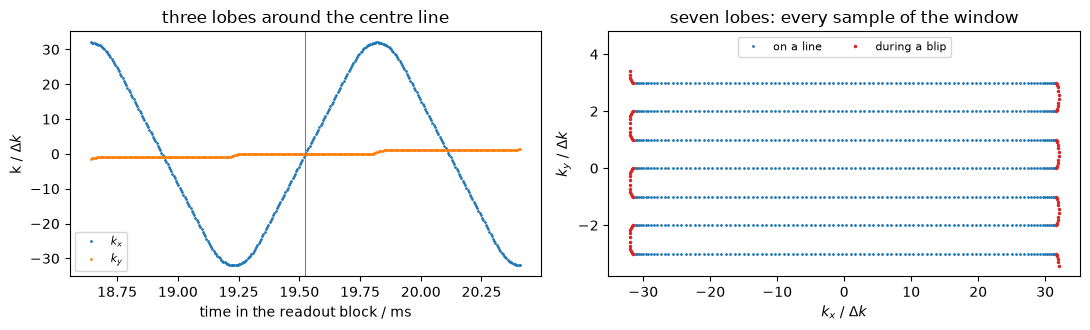

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
lobes = slice(readout.center_line - 1, readout.center_line + 2)
k_ro = readout.k_per_m(LINES)
times = readout.sample_times_s(LINES).reshape(len(LINES), S)[lobes].ravel() * 1e3
flat = ~between[lobes].ravel()
axes[0].plot(times, k_ro[0].reshape(len(LINES), S)[lobes].ravel() / DK, '.', ms=2, label='$k_x$')
axes[0].plot(times, k_ro[1].reshape(len(LINES), S)[lobes].ravel() / DK, '.', ms=2,
             label='$k_y$')
axes[0].axvline(readout.time_to_center_line(LINES) * 1e3, color='0.5', lw=0.8)
axes[0].set(xlabel='time in the readout block / ms', ylabel='k / $\\Delta k$',
            title='three lobes around the centre line')
axes[0].legend(fontsize=8, loc='lower left')

rows = slice(readout.center_line - 3, readout.center_line + 4)
kx_r = k_ro[0].reshape(len(LINES), S)[rows].ravel() / DK
ky_r = k_ro[1].reshape(len(LINES), S)[rows].ravel() / DK
on = ~between[rows].ravel()
axes[1].plot(kx_r[on], ky_r[on], '.', ms=2, color='C0', label='on a line')
axes[1].plot(kx_r[~on], ky_r[~on], '.', ms=3, color='C3', label='during a blip')
axes[1].set(xlabel='$k_x$ / $\\Delta k$', ylabel='$k_y$ / $\\Delta k$', ylim=(-3.8, 4.8),
            title='seven lobes: every sample of the window')
axes[1].legend(fontsize=8, loc='upper center', ncol=2)
fig.tight_layout()

Left, `kx` sweeps across a lobe and back while `ky` steps by one line at each turnaround; the grey
line is the echo time's endpoint, the midpoint of the centre line's lobe. Right, the same samples in
the k-space plane: the turnarounds, where the samples crowd together because the gradient passes
through zero, are also where the blips move `ky`.

## 5. The size of the window

The one ADC event holds `len(lines) × samples_per_echo` samples. It has to fit
`opts.adc_samples_limit`, and PyPulseq's timing check also requires every ADC event's sample count
to be a multiple of `opts.adc_samples_divisor` — 4 by default. The readout checks both when it
builds a train and refuses, rather than splitting the window into several events, which would
close the receiver for its dead time partway through the train.

Two refusals, each listing what would build instead:

In [7]:
def refused(what, call):
    try:
        call()
    except sc.ConfigurationError as error:
        text = str(error).splitlines()
        print(f'{what}\n  {text[0]}')
        for line in text[text.index('  fix') + 1:]:
            print(f'    - {line.strip()}')
        print()
    else:
        raise AssertionError(f'{what} was not refused')


tall = sc.modules.ContinuousEPI2D(opts=opts, fov_mm=(FOV_MM, 330.0), matrix=(64, 96),
                                  dwell_s=DWELL_S, oversampling=OVERSAMPLING)
refused('96 lines in one excitation (a 330 mm field of view along the blips)',
        lambda: tall(lines=range(96)))
refused('63 lines in one excitation', lambda: readout(lines=range(63)))

96 lines in one excitation (a 330 mm field of view along the blips)
  11328 ADC samples in this train's one ADC event (96 lines x 118 per echo), above the 8192 that opts.adc_samples_limit allows.
    - a table of at most 68 lines builds at this design: 69 fit one event, and 68 is the longest whose count opts.adc_samples_divisor = 4 divides
    - fewer lines per excitation changes the acquisition: more interleaved shots (shots with blip_lines) acquire the rest in other excitations, and a partial-ky table leaves lines unacquired for a partial-Fourier reconstruction to fill
    - oversampling=1 gives 98 samples per echo, so a table of up to 82 lines builds -- the flat-top sample spacing then reaches dk_read_per_m
    - EPI2D samples the same train with one ADC event per echo
    - this readout never splits its window into several events, which would put receiver dead time inside the train

63 lines in one excitation
  7434 ADC samples (63 lines x 118 per echo) is not a multiple of opts.ad

Of the remedies the 96-line refusal names, the one that keeps every line and the sampling is
**interleaving**: two excitations, each acquiring every other line. The blip then steps two lines,
and the second shot waits half an echo spacing so that the acquisition time stays a straight line
in `ky`.

In [8]:
interleaved = sc.modules.ContinuousEPI2D(opts=opts, fov_mm=(FOV_MM, 330.0), matrix=(64, 96),
                                         dwell_s=DWELL_S, oversampling=OVERSAMPLING,
                                         blip_lines=2, shots=2)
print(f'{interleaved.samples_per_echo} samples per echo, {interleaved.echo_spacing_s * 1e6:.0f} us '
      f'echo spacing; shot 1 waits {interleaved.shot_offset_s(1) * 1e6:.0f} us')
for segment in range(2):
    table = list(range(segment, 96, 2))
    events = [int(e.num_samples) for _, e, _ in sc.flatten(interleaved(lines=table, segment=segment))
              if e.type == 'adc']
    compiled(sc.LogicBlock('shot').add(0.0, interleaved(lines=table, segment=segment)))
    print(f'shot {segment}: {len(table)} lines, ADC events {events}, compiles')

120 samples per echo, 600 us echo spacing; shot 1 waits 300 us
shot 0: 48 lines, ADC events [5760], compiles
shot 1: 48 lines, ADC events [5760], compiles


## Limitations

- **No image is formed here.** The ramp samples are not evenly spaced in `kx` and the blip samples
  lie between `ky` lines, so a reconstruction has to grid from `k_per_m` (Bernstein et al.,
  p. 712, for ramp samples). This notebook builds and checks the acquisition; it does not simulate
  or reconstruct one.
- **The file was read back with PyPulseq, not played.** Whether a particular interpreter accepts a
  7552-sample event is what `adc_samples_limit` is set for; this notebook does not test any
  interpreter.
- **`oversampling` bounds the `kx` spacing only.** It does not establish that the two-dimensional
  sampling is adequate for a given reconstruction.
- **With `prephase=False`** — the spin-echo placement, where the dephasers go before the refocusing
  pulse — `k_per_m` and the echo instants describe a train that starts at
  `kx = −area_to_echo_per_m` and `ky = k_blip_per_m(lines[0])`. They are what the composition has to
  deliver, not a measurement of it.
- Navigator echoes, readout partial echo, a readout field-of-view offset and segmentation of the
  window by the interpreter are not part of this readout.

## Summary

| | |
|---|---|
| **the lobe is the window** | 118 samples × 5 µs = 590 µs exactly, on the gradient raster. The samples per echo follow from the dwell, the limits and `oversampling` |
| **`oversampling` is a bound** | the largest `kx` step, on the flat top, is `Δk / 1.5` here; it bounds the readout spacing and nothing two-dimensional |
| **`k = 0` is an instant** | each lobe's midpoint, between samples 58 and 59; `time_to_echo` and `time_to_center_line` report it |
| **one `kx` grid for both polarities** | a forward lobe and the reverse lobe after it, reversed, agree to 10⁻¹² Δk |
| **blips play on the ramps** | 12 samples of each interior lobe lie between lines; every other sample is on its line |
| **one ADC event per train** | 7552 samples against a limit of 8192; a table that does not fit, or whose count the divisor does not divide, is refused with what would build instead |
| **the file agrees** | sample times exactly, the trajectory within the file's six-digit amplitude rounding, and TE to well under a nanosecond |

## References

- Bernstein MA, King KF, Zhou XJ. *Handbook of MRI Pulse Sequences.* Elsevier, 2004, §16.1
  "Echo Planar Imaging": the prephaser of half the first readout lobe's area and the alternating
  readout polarity (Eq. 16.2, p. 707); sampling during the ramps (p. 708) and the gridding its
  unevenly spaced `kx` samples need (p. 712); blipped phase encoding, evenly spaced in `ky`
  (p. 717); the effective echo time, `TE(ky = 0)` (p. 719).